# Machine Learning Classification for Anti-Money Laundering

In this project, we will analyze an anti-money laundering dataset and build a ML classification model to classify wheter a transaction is money-laundering or not.

## Objectives

This notebook contains a project that will provide hands-on experience applying Supervised Machine Learning classification techniques to a real world dataset and communicating analytical findings. The project focuses on building, evaluating, and comparing multiple classification models to predict a binary outcome. Emphasis is placed on analytical rigor, model interpretability, and the clear presentation of insights that suppor data-driven decision-making.

First, lets import the required packages for this lab:

In [22]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, precision_recall_curve, ConfusionMatrixDisplay 


## Scenario: Anti-Money Laundering Detection

The dataset used for this porject contains a fixed synthetic benchmark instance generated using the AMLNet framework. It includes approximately 1.09 million transactions over a 195-day simulation period. The benchmark contains 1,411 suspicious transactions, corresponding to a suspicious rate of approximately 0.13%. This is a synthetic dataset, the patterns do not correspond to real world customers or banking activity. This data has only a purpose for machine learning experiments.

### Dataset Selection and Description

First of all, we load the dataset as a dataframe and take a look of the first rows:

In [2]:
file_URL = "https://zenodo.org/records/21237971/files/AMLNet_v2_transactions.csv?download=1"
df = pd.read_csv(file_URL)
df.head()

,step,type,amount,category,nameOrig,nameDest,oldbalanceOrg,newbalanceOrig,isFraud,isMoneyLaundering,laundering_typology,metadata,fraud_probability,hour,day_of_week,day_of_month,month
0,0,BPAY,121.231873,Food,C4638,C1811,332687.934283,332566.702410,0,0,normal,"{'timestamp': datetime.datetime(2025, 10, 13, ...",NaN,17,0,13,10
1,0,OSKO,98.099062,Other,C5536,C6852,455880.908413,455782.809350,0,0,normal,"{'timestamp': datetime.datetime(2025, 10, 13, ...",NaN,18,0,13,10
2,0,DEBIT,93.861773,Healthcare,C450,C4987,266729.197862,266635.336089,0,0,normal,"{'timestamp': datetime.datetime(2025, 10, 13, ...",NaN,18,0,13,10
3,0,BPAY,156.833185,Other,C503,C99,497635.915154,497479.081970,0,0,normal,"{'timestamp': datetime.datetime(2025, 10, 13, ...",NaN,18,0,13,10
4,0,DEBIT,63.286125,Transport,C4791,C7610,350189.092731,350125.806606,0,0,normal,"{'timestamp': datetime.datetime(2025, 10, 13, ...",NaN,19,0,13,10


In [3]:
df.shape

(1090000, 17)

We can see the dataset contains 17 columns with different information. We may discuss some of these columns to understand a little bit better what features the dataset contains and which ones will be useful the most:

- type: transaction type, such as DEBIT, TRANSFER or CASH_OUT.
- amount: transaction amount in Australian Dollars.
- category: transaction category, such as housing, food, transport...
- isMoneyLaundering: Binary AML label, where 1 indicates suspicious money laundering activity and 0 indicates ordinary activity, this will be our label to predict.
- isFraud: another Binary label that indicates if a transaction is suspicious or fraudulent.

Next, let's see how imbalanced this dataset is:

In [4]:
df['isMoneyLaundering'].value_counts(normalize=True)

isMoneyLaundering
0    0.998706
1    0.001294
Name: proportion, dtype: float64

<Axes: title={'center': 'Distribution of Money Laundering Cases'}, xlabel='Money Laundering Case', ylabel='Proportion'>

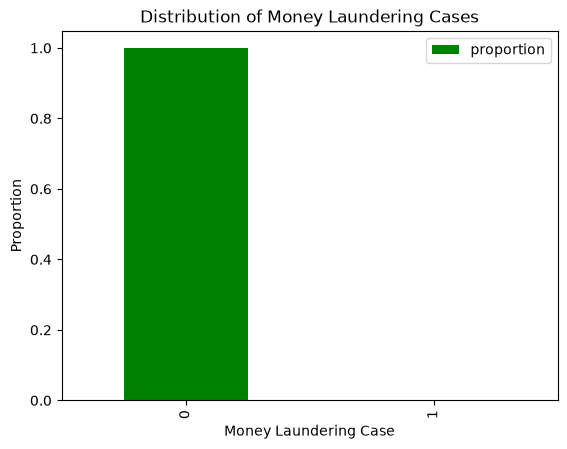

In [5]:
df['isMoneyLaundering'].value_counts(normalize=True).plot.bar(color=["green", "red"], title="Distribution of Money Laundering Cases", ylabel="Proportion",
                                                               xlabel="Money Laundering Case", legend=["Not Money Laundering", "Money Laundering"])

We see that only about 0.001% of the transactions are fraudulent, which tell us we are working with an extremely imbalance dataset.

### Analytical Approach and Model Development

Lets keep exploring the dataset to obtain a further view of how the information is structured and its quality.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1090000 entries, 0 to 1089999
Data columns (total 17 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   step                 1090000 non-null  int64  
 1   type                 1090000 non-null  str    
 2   amount               1090000 non-null  float64
 3   category             1090000 non-null  str    
 4   nameOrig             1090000 non-null  str    
 5   nameDest             1090000 non-null  str    
 6   oldbalanceOrg        1090000 non-null  float64
 7   newbalanceOrig       1090000 non-null  float64
 8   isFraud              1090000 non-null  int64  
 9   isMoneyLaundering    1090000 non-null  int64  
 10  laundering_typology  1090000 non-null  str    
 11  metadata             1090000 non-null  str    
 12  fraud_probability    1080000 non-null  float64
 13  hour                 1090000 non-null  int64  
 14  day_of_week          1090000 non-null  int64  
 15  day_of_mo

We see that 11 of our features are numerical, either float or integer values, and 6 features are categorical. We will have to discuss later if we encode these features, scale or apply other feature engineering methods to make them most valuable. Lets now check how many missing values do we have.

In [7]:
df.isnull().sum()

step                       0
type                       0
amount                     0
category                   0
nameOrig                   0
nameDest                   0
oldbalanceOrg              0
newbalanceOrig             0
isFraud                    0
isMoneyLaundering          0
laundering_typology        0
metadata                   0
fraud_probability      10000
hour                       0
day_of_week                0
day_of_month               0
month                      0
dtype: int64

We see that the only feature containing missing values is `fraud_probability`, checking the dataset info this column is a model-generated or risk-score field used in selected experiments. Since this feature is a probability calculed by another model, we will be dropping it for better training. In addition, other features such as `laundering_typlogy` are only true when the transaction is fraudulent, so we will be dropping it aswell so we don't train our model in a way it overfits. We will be dropping the `metadata` feature because it comes as a JSON and it will take quite a lot of time to parse and encode properly.

In [8]:
df = df.drop(columns=['laundering_typology', 'fraud_probability', 'isFraud', 'metadata'])

We will keep the rest of the features, since they seem all reasonable and useful to the model. Lets take a look to the categorical features and see if encoding is needed.

In [9]:
cat_columns = df.select_dtypes(include=['str']).columns
cat_df = df[cat_columns]
cat_df.head()

,type,category,nameOrig,nameDest
0,BPAY,Food,C4638,C1811
1,OSKO,Other,C5536,C6852
2,DEBIT,Healthcare,C450,C4987
3,BPAY,Other,C503,C99
4,DEBIT,Transport,C4791,C7610


`type` and `category` features are suitable for One-Hot Enconding. However, `nameOrig` and `NameDest` can't be treated this way since it would create thousands of new columns, we will have to perform feature engineering to better understand how this features can be interpreted. Let's start with the One-Hot Encoding:

In [10]:
# One Hot Encoding for categorical features
cols_ohe = ['type', 'category']

df = pd.get_dummies(df, columns=cols_ohe, drop_first=True, dtype=int)

print("New columns after One-Hot Encoding:", [col for col in df.columns if 'type_' in col or 'category_' in col])

New columns after One-Hot Encoding: ['type_CASH_OUT', 'type_DEBIT', 'type_EFTPOS', 'type_NPP', 'type_OSKO', 'type_PAYMENT', 'type_TRANSFER', 'category_Education', 'category_Food', 'category_Healthcare', 'category_Housing', 'category_Other', 'category_Property Investment', 'category_Recreation', 'category_Shell Company', 'category_Transport', 'category_Utilities']


In [11]:
df.shape

(1090000, 28)

After One-Hot Encoding, we have 12 more columns.

We will use feature engineering to encode the other two categorical features so we can obtain valuable information for our model. As we just discussed, the columns `nameOrig` and `nameDest` contain unique ids so we can't use One-Hot Encoding on them.

In Money Laundering detection, the predictive value is not in the specific ID, but in its behaviour and interaction pattern. We measure how active accounts are using the global frequency of sent and received transactions from every account.

In [12]:
# Global frequency of sent transactions by originator
orig_counts = df['nameOrig'].value_counts()
df['orig_tx_counts'] = df['nameOrig'].map(orig_counts)

# Global frequency of received transactions by recipient
dest_counts = df['nameDest'].value_counts()
df['dest_tx_counts'] = df['nameDest'].map(dest_counts)

The next step is creating the statistics for financial behavior.

In [13]:
# Mean, standard deviation, sum, minimum, and maximum transaction amounts for each originator
orig_stats = df.groupby('nameOrig')['amount'].agg(['mean', 'std', 'sum', 'min', 'max']).reset_index()
orig_stats.columns = ['nameOrig', 'orig_amount_mean', 'orig_amount_std', 'orig_amount_sum', 'orig_amount_min', 'orig_amount_max']

# Mean, standard deviation, sum, minimum, and maximum transaction amounts for each recipient
dest_stats = df.groupby('nameDest')['amount'].agg(['mean', 'std', 'sum', 'min', 'max']).reset_index()
dest_stats.columns = ['nameDest', 'dest_amount_mean', 'dest_amount_std', 'dest_amount_sum', 'dest_amount_min', 'dest_amount_max']

# Merging the statistics back to the original dataframe
df = df.merge(orig_stats, on='nameOrig', how='left')
df = df.merge(dest_stats, on='nameDest', how='left')

Create helpful indicators to detect suspicious transaction behaviours. 

In [14]:
# Is the origin account transfering itself?
df['is_same_orig_dest'] = (df['nameOrig'] == df['nameDest']).astype(int)

# Flag to find accounts that have been involved in money laundering transactions
# If nameOrig appears in nameDest
accounts_in_dest = set(df['nameDest'])
df['orig_is_also_dest'] = df['nameOrig'].isin(accounts_in_dest).astype(int)

Despite `oldbalanceOrig` and `newbalanceOrig` are separated columns, balance error is one of the strongests signals for money laundering.

In [15]:
# Balance error in origin
df['balance_error_orig'] = df['newbalanceOrig'] + df['amount'] - df['oldbalanceOrg']

# Balance error in destination
if 'oldbalanceDest' in df.columns and 'newbalanceDest' in df.columns:
    df['balance_error_dest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']

After obtaining all these new features, we don't need the ID's anymore, so we drop them from the dataframe.

In [16]:
df = df.drop(columns=['nameOrig', 'nameDest'])

We are done with the feature engineering, let's now prepare the dataset for training.

We will start using a `Time-Based Train/Test split`. Since transactions occur in a secuencial order, we must order the dataset chronologically and divide it.

In [17]:
# Make sure the dataframe is sorted by 'step' to maintain the chronological order of transactions
df = df.sort_values(by='step').reset_index(drop=True)

# Define the size for training and testing datasets
train_size = int(0.8 * len(df))

# Split the dataset into features (X) and target (y)
X = df.drop(columns=['isMoneyLaundering'])
y = df['isMoneyLaundering']

# Split the dataset into training and testing sets
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 872000 samples
Testing set size: 218000 samples


Once the dataset is ordered and properly split, we shall config the Class Weight. Since the positive class is less than 1%, if we train a model it will learn to always predict `0` and will achieve a great accuracy, but will never detect fraud. 

We will use XGBoost to automatically calculate the weights:

In [18]:
# Calculate proportions of the target variable in training and testing sets
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric='aucpr', # For unbalanced classes
    random_state=42
)

model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


The metrics we will use to evaluate the model will be `PR-AUC` (Precision-Recall Area Under Curve) since it is better for unbalanced classes, evaluating how well it detects real positives without false alarms. And also `Recall`, the percentage of real laundering casses that the model could predict.

We are also building a pipeline consisting of several models to find which one predicts better. We will build a `Logistic Regression`, a `Tree decision`, a `SVM model`, and a `LightGBM model` and compare which one performs best using the `PR-AUC` metric.

In [27]:
# 1. Define the transformers for categorical and numerical features

#Identify categorical and numerical columns
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
X_train[numeric_cols] = X_train[numeric_cols].fillna(0)
X_test[numeric_cols] = X_test[numeric_cols].fillna(0)

categorical_cols = X_train.select_dtypes(include=['uint8']).columns # Despite there being no categorical columns, we include this for future-proofing
X_train[categorical_cols] = X_train[categorical_cols].fillna('Undefined')
X_test[categorical_cols] = X_test[categorical_cols].fillna('Undefined')

#Preprocessing pipelines for both numeric and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='passthrough'  # This will keep any other columns that are not specified in the transformers
)

#2.- Define all four models configurations to manage the unbalanced dataset
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Support Vector Machine': LinearSVC(class_weight='balanced', max_iter=5000, random_state=42),
    'LightGBM': LGBMClassifier(is_unbalance=True, random_state=42),
    'XGBoost': xgb.XGBClassifier(scale_pos_weight=scale_pos_weight * 0.1, eval_metric='aucpr', random_state=42, max_depth=6, learning_rate=0.1, n_estimators=100, subsample=0.8, colsample_bytree=0.8)
}

#3.- Train and evaluate in a loop for each model
results = {}

for name, model in models.items():
    print(f"Training and evaluating model: {name}")

    # Create a pipeline that first preprocesses the data and then fits the model
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])

    # Fit the model
    pipeline.fit(X_train, y_train)

    # Make predictions
    classifier_step = pipeline.named_steps['classifier']
    
    if hasattr(classifier_step, "predict_proba"):
        y_pred_scores = pipeline.predict_proba(X_test)[:, 1]
    else:
        # For LinearSVC (uses the distance to the hyperplane as a score)
        y_pred_scores = pipeline.decision_function(X_test)

    # Calculate PR-AUC
    pr_auc = average_precision_score(y_test, y_pred_scores)
    results[name] = pr_auc

    print(f"{name} PR-AUC: {pr_auc:.4f}\n")

# 4.- Display the results
print("Model Performance (PR-AUC):")
for name, pr_auc in results.items():
    print(f"{name}: {pr_auc:.4f}")

Training and evaluating model: Logistic Regression
Logistic Regression PR-AUC: 0.6883

Training and evaluating model: Decision Tree
Decision Tree PR-AUC: 0.7186

Training and evaluating model: Support Vector Machine
Support Vector Machine PR-AUC: 0.7161

Training and evaluating model: LightGBM
[LightGBM] [Info] Number of positive: 1235, number of negative: 870765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.066233 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3964
[LightGBM] [Info] Number of data points in the train set: 872000, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.001416 -> initscore=-6.558301
[LightGBM] [Info] Start training from score -6.558301
LightGBM PR-AUC: 0.0538

Training and evaluating model: XGBoost
XGBoost PR-AUC: 0.9314

Model Performance (PR-AUC):
Logistic Regression: 0.6883
De

After obtaining these results, we can select the model that performed better and analyze how well it predicts on our data.


### Model Selection and Justification

By comparing the `PR_AUC` obtained by each of the built models, we can select the best-performing classification model. The `XGBoost` model is the one with the best `PR-AUC`, with 0.9178. Its performance is by far the best from all the models we have built.
In terms of interpretability, this model is based on feature importance, which grants a way to understand how it predicts using tools like SHAP for better interpretability. Talking robustness, XGBoost is one of the best models since it codifies non-linear relations between features inherently.

Lets check other evaluation metrics for this model to better conclude why we select it for this task. Starting with the confussion matrix:

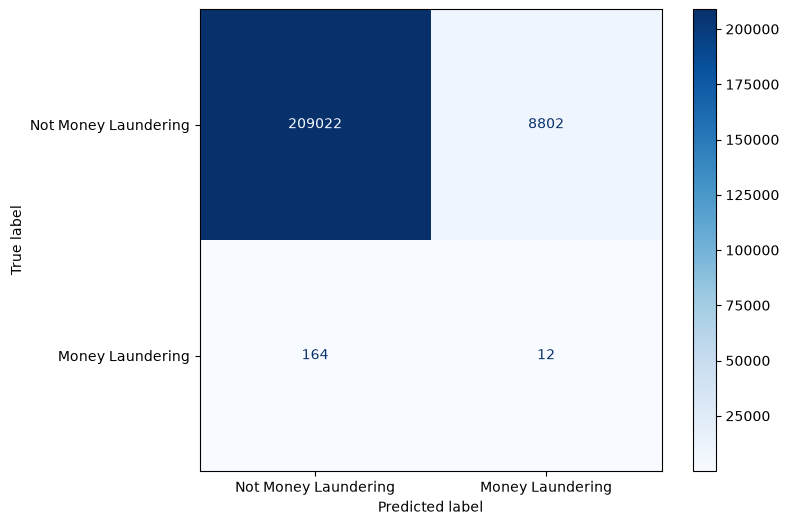

In [28]:
# 1.- Obtain the predicted probabilities for the best model (XGBoost in this case)
y_pred_proba = models['XGBoost'].predict_proba(X_test)[:, 1]

# 2.- Set the threshold for classification.
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)

# Find the threshold that maximizes the F1 score
best_threshold_idx = np.argmax(f1_scores)
threshold = thresholds[best_threshold_idx]

y_pred = (y_pred_proba >= threshold).astype(int)

# 3.- Confussion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels=['Not Money Laundering', 'Money Laundering'],
                                       cmap='Blues', normalize=None, ax=ax)

We must see what features are the most important to understand better how the model predicts, lets do some interpretation based on feature importance:

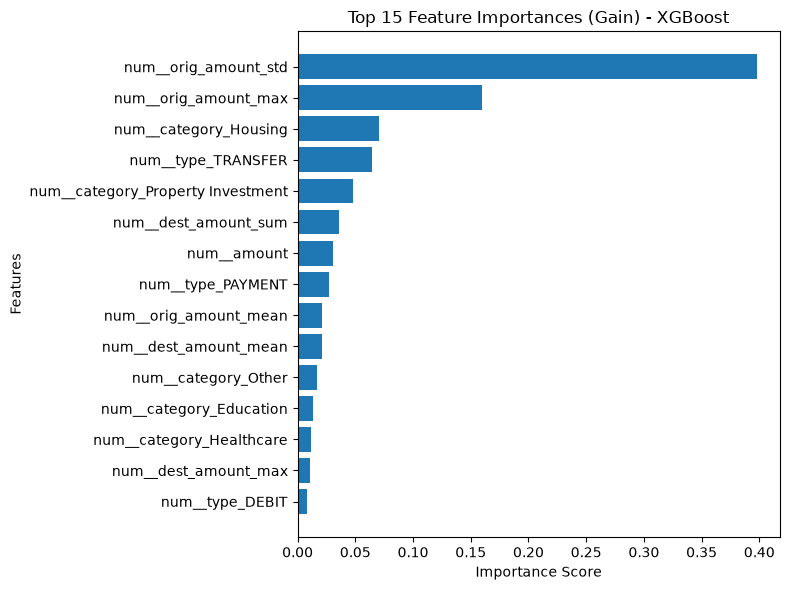

In [35]:
preprocessor = pipeline.named_steps['preprocessor']
xgb_model = pipeline.named_steps['classifier']

# 2. Extraer los nombres de las columnas procesadas automáticamente por el ColumnTransformer
# (Scikit-learn moderno tiene el método get_feature_names_out)
try:
    feature_names = preprocessor.get_feature_names_out()
except AttributeError:
    # Si usas una versión anterior de scikit-learn, puedes reconstruirlos manualmente:
    # (Pero get_feature_names_out() está disponible desde la versión 1.0)
    feature_names = numeric_cols.tolist() + list(preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(categorical_cols))

# 3. Crear un DataFrame o asociar las importancias con sus nombres reales
importances = xgb_model.feature_importances_

# Crear un DataFrame ordenado de mayor a menor importancia
df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True) # Ascending True para que el gráfico horizontal los ordene bien
plt.figure(figsize=(8, 6))
plt.barh(df_importance['Feature'].tail(15), df_importance['Importance'].tail(15))
plt.title("Top 15 Feature Importances (Gain) - XGBoost")
plt.ylabel("Features")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

### Key findings and Insights

We found that the best model to predict the money laundering scenario is `XGBoost`. It showed how features that quantify the amount of money coming from transactions are the most important to predict wheter a transaction is fraudulent or not, with `num_orig_amount_std` and `num_orig_amount_max` being the most important ones. 

This results align with the project objetives since the pipeline can be dynamically adjusted to match capacity of the analysis because of the severe class imbalance. In addition, the feature importance explainability tools allow to justify flagged transactions, balancing properly the balanace between high detection ratio and operational efficiency.

### Limitations and Future Work

To ensure the long-term viability of the AML pipeline, we must address several limitations and future improvements:

#### Limitations:

 * Persistent False Positives: Despite achieving a high PR-AUC and tuning the decision thresholds, the extreme class imbalance generates a high volume of false alarms.

 * Interpretability vs. Complexity trade-off: while XGBoost handles non-linear relationships and interactions, it remains a complex ensemble model. Without explainability tools such as SHAP, interpreting individual predictions for regulatory purposes can be difficult compared to linear models.

 * Data Quality and Missing context: we are not accounting external metadata that could further reduce ambiguity.

 #### Future work and improvements:

 * Advanced imbalance strategies: move beyond basic weighting using resampling techniques such as SMOTE.

 * Implement Graph-Based Feature Engineering.
